# HW1: SIR and SEIR Model

## Part A: SIR Model

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Basic parameters
N = 2000

S0 = 1995
I0 = 5
R0 = 0

beta = 0.125e-3
gamma = 0.1

# Simulation time
days = 160
dt = 0.1

In [2]:
# SIR model
def sir_model(S, I, R, beta, gamma):

    # Calculate the change of S, I and R
    dS = -beta * S * I
    dI = beta * S * I - gamma * I
    dR = gamma * I

    return dS, dI, dR

In [3]:
dS, dI, dR = sir_model(S0, I0, R0, beta, gamma)

print(dS, dI, dR)
print("Total change:", dS + dI + dR)

-1.2468750000000002 0.7468750000000002 0.5
Total change: 0.0


## Part B: SIR simulation

Forward Euler uses the rates at the previous time step to update each population: `new value = old value + dt * rate`. All three rates must use the same previous values.

The simulation starts with 1,995 susceptible, 5 infected, and 0 recovered people. Since `dS + dI + dR = 0`, the total population should stay at 2,000, apart from tiny floating-point rounding errors.


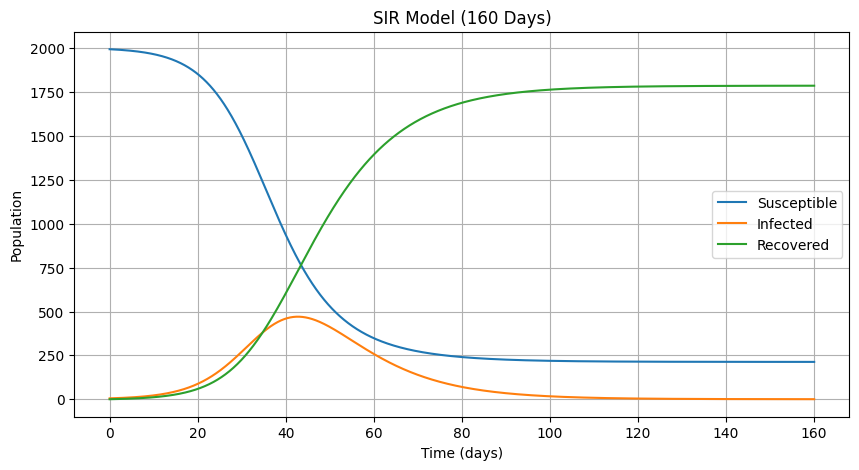

In [4]:

# Set time
time = np.arange(0, days + dt, dt)

# Save the results
S = np.zeros(len(time))
I = np.zeros(len(time))
R = np.zeros(len(time))

# Set initial values
S[0] = S0
I[0] = I0
R[0] = R0

# Euler method
for i in range(1, len(time)):
    dS, dI, dR = sir_model(S[i-1], I[i-1], R[i-1], beta, gamma)

    S[i] = S[i-1] + dS * dt
    I[i] = I[i-1] + dI * dt
    R[i] = R[i-1] + dR * dt

# Plot SIR results
plt.figure(figsize=(10, 5))
plt.plot(time, S, label="Susceptible")
plt.plot(time, I, label="Infected")
plt.plot(time, R, label="Recovered")

plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title(f"SIR Model ({days} Days)")
plt.legend()
plt.grid(True)
plt.show()


In [5]:
# Report the infection peak and check population conservation
peak_index = np.argmax(I)
total_population = S + I + R

print(f"Peak infected: {I[peak_index]:.2f} people on day {time[peak_index]:.1f}")
print(f"Maximum population error: {np.max(np.abs(total_population - N)):.2e}")
assert np.allclose(total_population, N, rtol=0, atol=1e-9), "Population is not conserved"


Peak infected: 470.46 people on day 42.7
Maximum population error: 2.73e-12


## Part C: Analysis and interpretation


In [6]:

# Calculate basic reproduction number
R0_sir = beta * N / gamma

# Populations at the end of the 160-day simulation
print("R0:", round(R0_sir, 2))
print("Day 160 S (never infected):", round(S[-1], 2))
print("Day 160 I:", round(I[-1], 2))
print("Day 160 R:", round(R[-1], 2))

# Calculate results for comparison with my hypothesis
print("Peak infected:", round(np.max(I), 2))
print("Peak day:", round(time[np.argmax(I)], 1))



R0: 2.5
Final S: 212.79
Final I: 0.2
Final R: 1787.01
Peak infected: 470.46
Peak day: 42.7


## Part D: SEIR model


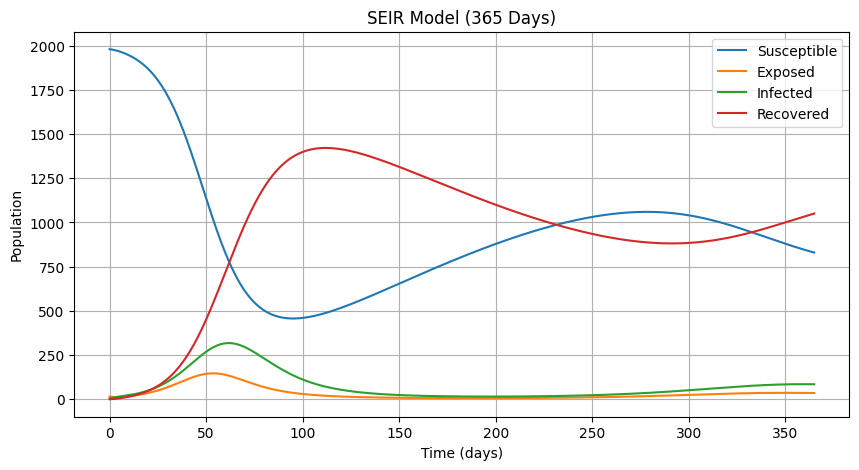

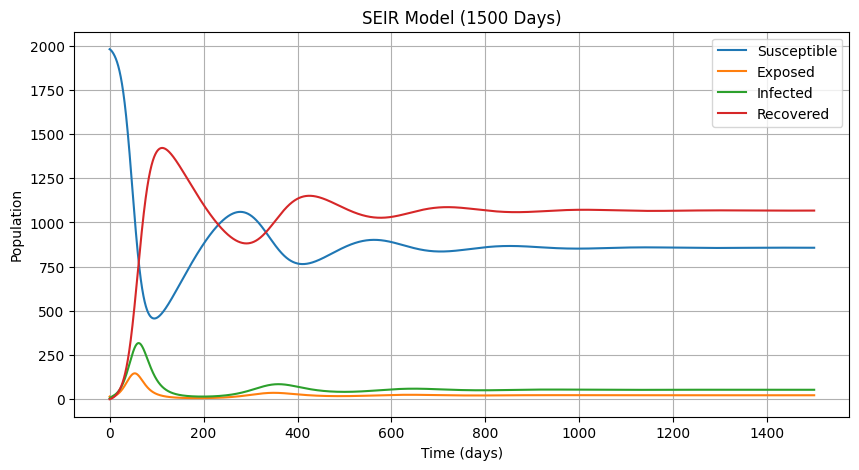

In [7]:

def seir_model(S, E, I, R, beta, gamma, sigma, mu):
    dS = mu * N - beta * S * I - mu * S
    dE = beta * S * I - sigma * E - mu * E
    dI = sigma * E - gamma * I - mu * I
    dR = gamma * I - mu * R

    return dS, dE, dI, dR


# SEIR parameters
sigma = 0.25
mu = 0.005

S0_seir = 1980
E0_seir = 15
I0_seir = 5
R0_seir_initial = 0


# Euler method for SEIR
def run_seir(days):
    time_seir = np.arange(0, days + dt, dt)

    S = np.zeros(len(time_seir))
    E = np.zeros(len(time_seir))
    I = np.zeros(len(time_seir))
    R = np.zeros(len(time_seir))

    S[0] = S0_seir
    E[0] = E0_seir
    I[0] = I0_seir
    R[0] = R0_seir_initial

    for i in range(1, len(time_seir)):
        dS, dE, dI, dR = seir_model(
            S[i-1], E[i-1], I[i-1], R[i-1],
            beta, gamma, sigma, mu
        )

        S[i] = S[i-1] + dS * dt
        E[i] = E[i-1] + dE * dt
        I[i] = I[i-1] + dI * dt
        R[i] = R[i-1] + dR * dt

    return time_seir, S, E, I, R


# Plot 365 and 1500 days
for simulation_days in [365, 1500]:
    t, S_seir, E_seir, I_seir, R_seir = run_seir(simulation_days)

    # Check total population and report each local infection peak
    total = S_seir + E_seir + I_seir + R_seir
    assert np.allclose(total, N, rtol=0, atol=1e-9), "Population is not conserved"
    peaks = np.where((I_seir[1:-1] > I_seir[:-2]) &
                     (I_seir[1:-1] >= I_seir[2:]))[0] + 1

    print(f"\n{simulation_days}-day simulation")
    print(f"Maximum population error: {np.max(np.abs(total - N)):.2e}")
    for wave, index in enumerate(peaks, start=1):
        print(f"Wave {wave}: day {t[index]:.1f}, infected = {I_seir[index]:.2f}")
    print(f"Final S, E, I, R: {S_seir[-1]:.2f}, {E_seir[-1]:.2f}, "
          f"{I_seir[-1]:.2f}, {R_seir[-1]:.2f}")

    plt.figure(figsize=(10, 5))
    plt.plot(t, S_seir, label="Susceptible")
    plt.plot(t, E_seir, label="Exposed")
    plt.plot(t, I_seir, label="Infected")
    plt.plot(t, R_seir, label="Recovered")

    plt.xlabel("Time (days)")
    plt.ylabel("Population")
    plt.title(f"SEIR Model ({simulation_days} Days)")
    plt.legend()
    plt.grid(True)
    plt.show()


In [8]:
# Basic reproduction number and endemic equilibrium
R0_seir = beta * N * sigma / ((sigma + mu) * (gamma + mu))
print(f"SIR R0: {R0_sir:.4f}")
print(f"SEIR R0: {R0_seir:.4f}")

if R0_seir > 1:
    S_eq = N / R0_seir
    I_eq = mu * (N - S_eq) / (beta * S_eq)
    E_eq = (gamma + mu) * I_eq / sigma
    R_eq = gamma * I_eq / mu
    print(f"Equilibrium S, E, I, R: {S_eq:.2f}, {E_eq:.2f}, {I_eq:.2f}, {R_eq:.2f}")
    print(f"Day 1500 S: {S_seir[-1]:.2f}; N/R0: {S_eq:.2f}")


SIR R0: 2.5000
SEIR R0: 2.3343
Equilibrium S, E, I, R: 856.80, 22.42, 53.37, 1067.41
Day 1500 S: 856.92; N/R0: 856.80


## Part E: Parameter sensitivity


In [ ]:
beta_values = np.linspace(0.05e-3, 0.25e-3, 5)
gamma_values = np.linspace(0.05, 0.25, 5)


def run_sensitivity(step_size):
    peak_results = np.zeros((len(beta_values), len(gamma_values)))
    total_results = np.zeros_like(peak_results)

    for i, b in enumerate(beta_values):
        for j, g in enumerate(gamma_values):
            S_e, E_e, I_e, R_e = 1980.0, 15.0, 5.0, 0.0
            peak_I = I_e
            total_infections = 0.0

            for step in range(round(365 / step_size)):
                dS, dE, dI, dR = seir_model(
                    S_e, E_e, I_e, R_e, b, g, sigma, mu
                )
                # Count new infections (S -> E), using the old populations.
                total_infections += b * S_e * I_e * step_size
                S_e += dS * step_size
                E_e += dE * step_size
                I_e += dI * step_size
                R_e += dR * step_size
                peak_I = max(peak_I, I_e)

            peak_results[i, j] = peak_I
            total_results[i, j] = total_infections

    return peak_results, total_results


peak_results, total_results = run_sensitivity(dt)

# R0 = 1 implies beta = (sigma + mu) * (gamma + mu) / (N * sigma).
gamma_boundary = np.linspace(gamma_values[0], gamma_values[-1], 200)
beta_boundary = (sigma + mu) * (gamma_boundary + mu) / (N * sigma)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
plots = [
    (peak_results, "Peak infectious population", "People", "viridis"),
    (total_results, "Cumulative new infections", "New infections", "magma"),
]

for ax, (data, title, units, colors) in zip(axes, plots):
    image = ax.pcolormesh(
        gamma_values, beta_values * 1000, data,
        shading="nearest", cmap=colors
    )
    # White outline keeps the dashed boundary visible on both heatmaps.
    ax.plot(gamma_boundary, beta_boundary * 1000, color="white", linewidth=4)
    ax.plot(gamma_boundary, beta_boundary * 1000, "k--", linewidth=2,
            label=r"$R_0 = 1$")

    for i, b in enumerate(beta_values):
        for j, g in enumerate(gamma_values):
            text_color = "black" if image.norm(data[i, j]) > 0.65 else "white"
            ax.text(g, b * 1000, f"{data[i, j]:.1f}", ha="center",
                    va="center", color=text_color, fontsize=10,
                    bbox=dict(facecolor=image.cmap(image.norm(data[i, j])),
                              edgecolor="none", alpha=0.95, pad=1.5))

    ax.set_xticks(gamma_values)
    ax.set_xticklabels([f"{g:.2f}" for g in gamma_values])
    ax.set_yticks(beta_values * 1000)
    ax.set_yticklabels([f"{b * 1000:.2f}" for b in beta_values])
    ax.set_xlabel(r"Recovery rate $\gamma$ (per day)", fontsize=11)
    ax.set_ylabel(r"Transmission rate $\beta$ ($10^{-3}$ per person per day)", fontsize=11)
    ax.set_title(title + " (first 365 days)", fontsize=12)
    ax.legend(loc="upper left", facecolor="white", framealpha=1)
    fig.colorbar(image, ax=ax, label=units, shrink=0.85)

plt.show()
